# COMP8410 A1 - Week 4 (Nerfacto vs 3D Gaussian Splatting) - Colab
Runtime: **L4 or A100 GPU** (24 GB is enough). Upload the 105 bedroom photos once to Drive as `comp8410_a1/w4_data/setA/`.
Before saving: Edit > Notebook settings > tick *Omit code cell output when saving* (the outputs show a private room). Never use *Save a copy in GitHub*.
Order: Cell 1-2 setup, Cell 3 smoke tests, Cell 4 full run, Cell 5 results. **Disconnect the runtime when finished** (last cell).


## Cell 1: Drive, code, packages, COLMAP, nerfstudio


In [12]:
%cd /content
from google.colab import drive
import os
drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/comp8410_a1'
for d in ['results', 'outputs', 'logs', 'w4_data']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)

!rm -rf /content/a1 && git clone https://github.com/yash1998-MQ-AI/COMP8410-A1-48576158.git /content/a1
%cd "/content/a1/48576158 Evaluation"
!pip -q install -r requirements.txt
!pip -q install lpips tabulate imageio imageio-ffmpeg
!apt-get -qq install -y colmap ffmpeg > /dev/null 2>&1; colmap -h 2>&1 | head -1
!python pairs/w4_nerf_3dgs/install_nerfstudio.py 2>&1 | tail -6


/content
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/a1'...
remote: Enumerating objects: 238, done.
remote: Counting objects: 100% (238/238), done.
remote: Compressing objects: 100% (129/129), done.
remote: Total 238 (delta 98), reused 232 (delta 92), pack-reused 0 (from 0)
Receiving objects: 100% (238/238), 435.13 KiB | 10.88 MiB/s, done.
Resolving deltas: 100% (98/98), done.
/content/a1/48576158 Evaluation
COLMAP 3.7 -- Structure-from-Motion and Multi-View Stereo
installing 44 requirements
wrote /usr/local/lib/python3.12/dist-packages/fpsample.py


In [13]:
!apt-get -qq update && apt-get -qq install -y colmap ffmpeg 2>&1 | tail -5
!which colmap && colmap -h 2>&1 | head -1

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
/usr/bin/colmap
COLMAP 3.7 -- Structure-from-Motion and Multi-View Stereo


In [19]:
!git -C /content/a1 pull

remote: Enumerating objects: 11, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.02 KiB | 1.02 MiB/s, done.
From https://github.com/yash1998-MQ-AI/COMP8410-A1-48576158
   f476b14..fa35a85  main       -> origin/main
Updating f476b14..fa35a85
Fast-forward
 48576158 Evaluation/pairs/w4_nerf_3dgs/score_w4.py | 23 +++++++++++++++++++---
 1 file changed, 20 insertions(+), 3 deletions(-)


## Cell 2: link Drive folders, GPU check, import check
The import check is the part most likely to fail on Colab's newest Python (nerfacc compiles CUDA code the first time it is imported, which can take a few minutes). If it fails, copy the last lines and stop here.


In [14]:
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
!rm -rf results outputs
!ln -s {BASE}/results results
!ln -s {BASE}/outputs outputs
!mkdir -p {BASE}/outputs/w4_figures
!nvidia-smi --query-gpu=name,memory.total --format=csv
!python -m pytest -q tests/test_w4.py
!python -c "import torch, nerfacc, gsplat, nerfstudio; print('torch', torch.__version__, 'cuda', torch.version.cuda); print('IMPORT CHECK PASSED')" 2>&1 | tail -15
!ns-train --help 2>&1 | head -3
!echo photos on Drive: && ls {BASE}/w4_data/setA | wc -l


name, memory.total [MiB]
NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB
...........                                                              [100%]
11 passed in 0.72s
torch 2.11.0+cu128 cuda 12.8
IMPORT CHECK PASSED
2026-10-30 12:22:39.810992: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-30 12:22:39.843725: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
photos on Drive:
105


## Cell 3: smoke tests (30 photos, 200 iterations, 1 seed). Results go to separate smoke files, not the real ones.
Run the four cells in order. The last one prints SMOKE PASSED or SMOKE FAILED and shows one held-out view from each model.


In [15]:
# 3a. COLMAP on 30 photos (CPU, a few minutes). Prints how many photos it could place.
!python pairs/w4_nerf_3dgs/run_w4.py process --images {BASE}/w4_data/setA --limit 30 2>&1 | tee {BASE}/logs/w4_smoke_process.log | tail -25


I20261030 12:23:18.159941 139449125273600 incremental_pipeline.cc:623] => Image sees 101 / 664 points
I20261030 12:23:18.226334 139449125273600 incremental_pipeline.cc:88] Retriangulation and Global bundle adjustment
I20261030 12:23:18.725650 139449125273600 incremental_pipeline.cc:88] Retriangulation and Global bundle adjustment
I20261030 12:23:18.936211 139449125273600 incremental_pipeline.cc:826] Keeping successful reconstruction
I20261030 12:23:18.944005 139449125273600 timer.cc:90] Elapsed time: 0.321 [minutes]
pycolmap 4.2.1: 2 model(s), best has 29 registered images
{
  "n_input": 30,
  "n_registered": 29,
  "fraction_registered": 0.9667,
  "matching": "exhaustive",
  "max_side": 1440,
  "pose_tool": "pycolmap 4.2.1",
  "dropped_other_size": [
    "1000025388.jpeg",
    "1000025389.jpeg",
    "1000025390.jpeg",
    "1000025391.jpeg",
    "1000025393.jpeg"
  ],
  "process_seconds": 23.9,
  "min_required": 0.9,
  "gate_passed": true
}
GATE PASSED: 29/30 frames registered


In [16]:
# 3b. train both models for 200 iterations
!python pairs/w4_nerf_3dgs/run_w4.py train --models nerfacto splatfacto --seeds 0 --iters 200 --results results/w4_smoke.jsonl --ns-out /content/ns_smoke --ignore-gate 2>&1 | tee {BASE}/logs/w4_smoke_train.log | tail -30


130 (65.00%)        3.937 ms             275.605 ms           98.99 M               
140 (70.00%)        4.008 ms             240.475 ms           97.20 M               
150 (75.00%)        3.989 ms             199.431 ms           97.70 M               
160 (80.00%)        3.944 ms             157.749 ms           98.76 M               
170 (85.00%)        3.952 ms             118.563 ms           98.51 M               
180 (90.00%)        4.021 ms             80.417 ms            96.90 M               
190 (95.00%)        4.050 ms             40.504 ms            96.21 M               
Step (% Done)                                                                       
--------------------                                                                
110 (55.00%)        3.990 ms             359.116 ms           97.65 M               
120 (60.00%)        3.956 ms             316.504 ms           98.53 M               
130 (65.00%)        3.937 ms             275.605 ms           98.

In [20]:
# 3c. render the held-out views and score them
!python pairs/w4_nerf_3dgs/score_w4.py --models nerfacto splatfacto --seeds 0 --results results/w4_smoke.jsonl --ns-out /content/ns_smoke --out-root /content/smoke_out 2>&1 | tee {BASE}/logs/w4_smoke_score.log | tail -30


  cx, cy = self.cx[true_indices].squeeze(-1), self.cy[true_indices].squeeze(-1)  # (num_rays,)
/usr/local/lib/python3.12/dist-packages/nerfstudio/cameras/cameras.py:639: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  distortion_params = self.distortion_params[true_indices]
/usr/local/lib/python3.12/dist-packages/nerfstudio/cameras/cameras.py:647: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered intern

SMOKE PASSED
nerfacto {'train_time_s': 73.89, 'peak_vram_gb': 4.08, 'render_fps': 0.44}
splatfacto {'train_time_s': 295.39, 'peak_vram_gb': 0.84, 'render_fps': 4.27}


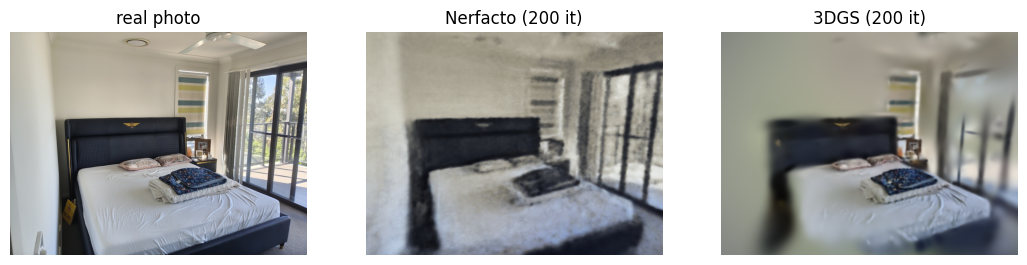

In [21]:
# 3d. smoke verdict and one picture
import glob, matplotlib.pyplot as plt
from PIL import Image
from a1eval import load
rows = load('results/w4_smoke.jsonl')
need = {(m, k) for m in ('nerfacto', 'splatfacto') for k in ('psnr', 'ssim', 'lpips', 'train_time_s', 'render_fps')}
got = {(r.model, r.metric) for r in rows}
print('SMOKE PASSED' if need <= got else f'SMOKE FAILED, missing: {sorted(need - got)}')
for m in ('nerfacto', 'splatfacto'):
    t = {r.metric: r.value for r in rows if r.model == m and r.metric in ('train_time_s', 'render_fps', 'peak_vram_gb')}
    print(m, {k: round(v, 2) for k, v in t.items()})
gt = sorted(glob.glob('/content/smoke_out/w4/gt/*.png'))
if gt:
    name = gt[0].rsplit('/', 1)[1]
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
    for a, (t, p) in zip(ax, [('real photo', gt[0]), ('Nerfacto (200 it)', f'/content/smoke_out/w4/nerfacto/s0/{name}'), ('3DGS (200 it)', f'/content/smoke_out/w4/splatfacto/s0/{name}')]):
        a.imshow(Image.open(p)); a.set_title(t); a.axis('off')
    plt.show()


## Cell 4: full run (all 105 photos, both models, 3 seeds, 30,000 iterations each)
COLMAP is run once. If its gate fails (fewer than 90% of the photos placed) the training cell refuses to start: fix the photos first rather than training on a broken scene. Training is resumable: finished runs are skipped.


In [22]:
# 4a. COLMAP on all photos
!python pairs/w4_nerf_3dgs/run_w4.py process --images {BASE}/w4_data/setA 2>&1 | tee {BASE}/logs/w4_process.log | tail -25


I20261030 12:38:05.177537 133378338033664 incremental_pipeline.cc:623] => Image sees 50 / 1170 points
I20261030 12:38:05.285084 133378338033664 incremental_pipeline.cc:88] Retriangulation and Global bundle adjustment
I20261030 12:38:09.439530 133378338033664 incremental_pipeline.cc:88] Retriangulation and Global bundle adjustment
I20261030 12:38:11.477593 133378338033664 incremental_pipeline.cc:826] Keeping successful reconstruction
I20261030 12:38:11.506170 133378338033664 timer.cc:90] Elapsed time: 1.442 [minutes]
pycolmap 4.2.1: 1 model(s), best has 99 registered images
{
  "n_input": 100,
  "n_registered": 99,
  "fraction_registered": 0.99,
  "matching": "exhaustive",
  "max_side": 1440,
  "pose_tool": "pycolmap 4.2.1",
  "dropped_other_size": [
    "1000025388.jpeg",
    "1000025389.jpeg",
    "1000025390.jpeg",
    "1000025391.jpeg",
    "1000025393.jpeg"
  ],
  "process_seconds": 100.4,
  "min_required": 0.9,
  "gate_passed": true
}
GATE PASSED: 99/100 frames registered


In [23]:
# 4b. train 2 models x 3 seeds
!python pairs/w4_nerf_3dgs/run_w4.py train --models nerfacto splatfacto --seeds 0 1 2 --ns-out /content/ns_runs 2>&1 | tee {BASE}/logs/w4_train.log | grep -v Warning | tail -30


29930 (99.77%)      5.132 ms             359.238 ms           76.64 M               
29940 (99.80%)      5.061 ms             303.635 ms           77.57 M               
29950 (99.83%)      5.047 ms             252.370 ms           77.82 M               
29960 (99.87%)      5.028 ms             201.116 ms           78.29 M               
29970 (99.90%)      5.088 ms             152.637 ms           77.38 M               
29980 (99.93%)      5.168 ms             103.358 ms           76.06 M               
29990 (99.97%)      5.114 ms             51.141 ms            76.85 M               
Step (% Done)                                                                       
--------------------                                                                
29910 (99.70%)      5.024 ms             452.171 ms           78.18 M               
29920 (99.73%)      5.100 ms             408.017 ms           77.18 M               
29930 (99.77%)      5.132 ms             359.238 ms           76.

In [24]:
# 4c. render held-out views and score them
!python pairs/w4_nerf_3dgs/score_w4.py --models nerfacto splatfacto --seeds 0 1 2 --ns-out /content/ns_runs 2>&1 | tee {BASE}/logs/w4_score.log | tail -20




🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch


🏃 🏃 Install tcnn for speedups 🏃 🏃
pip install git+https://github.com/NVlabs/tiny-cuda-nn/#subdirectory=bindings/torch

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from /content/ns_runs/nerfacto_s2/nerfacto/run/nerfstudio_models/step-000029999.ckpt
Loading latest checkpoint from load_dir
✅ Done loading checkpoint from /content/ns_runs/splatfacto_s0/splatfacto/run/nerfstudio_models/step-000029999.ckpt
Loading latest checkpoint from load_dir
✅ Done loading checkpoint from /content/ns_runs/splatfacto_s1/splatfacto/run/nerfstudio_models/step-000029999.ckpt
Loading latest checkpoint from load_dir
✅ Done loading checkpoint from /content/ns_runs/splatfacto_s2/splatfacto/run/nerfstudio_models/step-000029999.ckpt
appended 243 metric rows to /content/a1/48576158 Evaluation/results/w4.jsonl


## Cell 5: tables, charts, pictures and the side-by-side clip
While connected, read this GPU's compute units per hour from the Resources panel and type it into `UNITS_PER_HR` so the training cost is priced. Keep *Omit code cell output when saving* ticked: the pictures show the room.


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (2160, 542) to (2160, 544) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
[rawvideo @ 0x2b1e4040] Stream #0: not enough frames to estimate rate; consider increasing probesize

== held-out views, per model ==
 metric      model  n_views   mean     lo     hi
 lpips   nerfacto       13  0.247  0.198  0.303
 lpips splatfacto       13  0.198  0.156  0.245
  psnr   nerfacto       13 19.763 18.065 21.287
  psnr splatfacto       13 22.188 20.507 23.803
  ssim   nerfacto       13  0.707  0.643  0.763
  ssim splatfacto       13  0.768  0.716  0.815

== 3DGS minus Nerfacto, paired over photos ==
 metric  n_views  splatfacto_mean  nerfacto_mean   diff     lo     hi significant
 lpips       13            0.198          0.247 -0.049 -0.075 -0.026         y

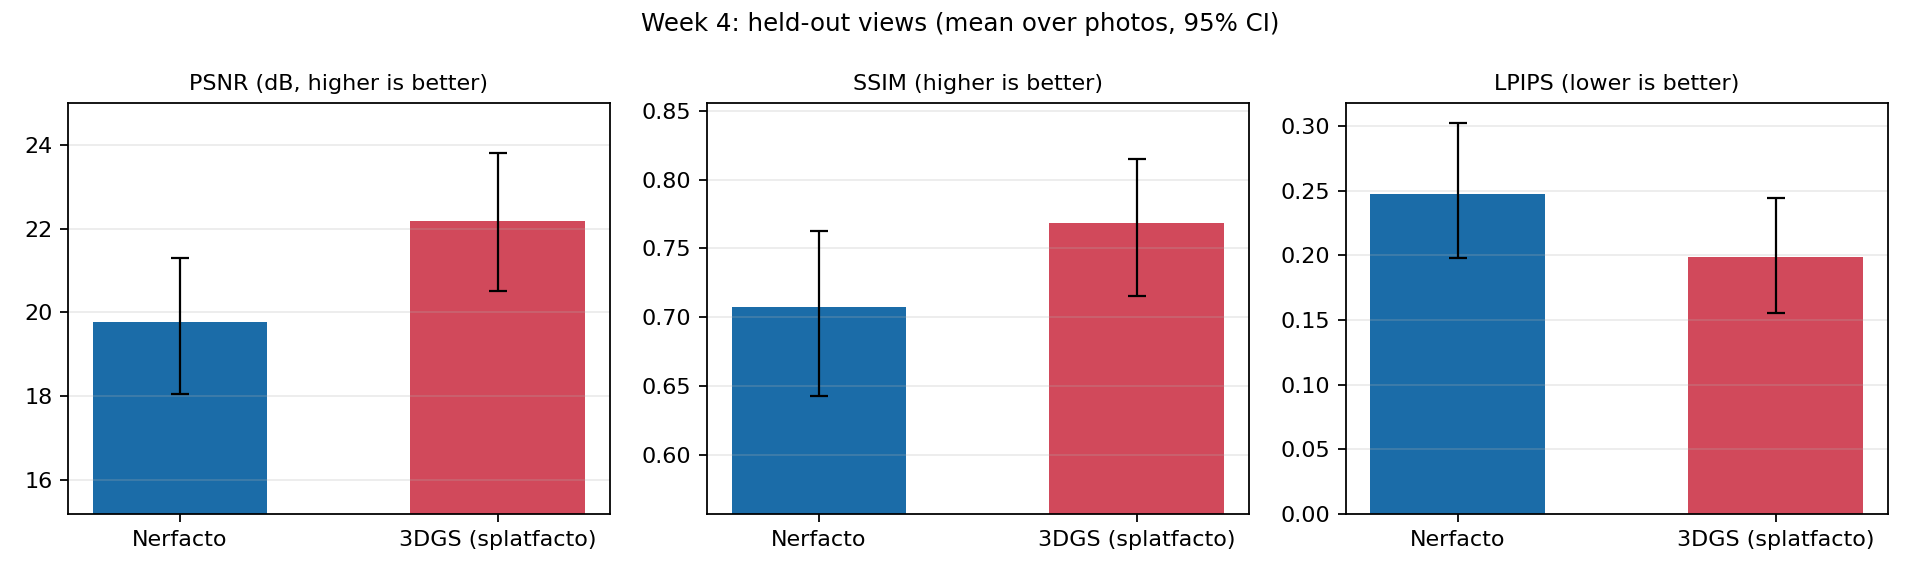

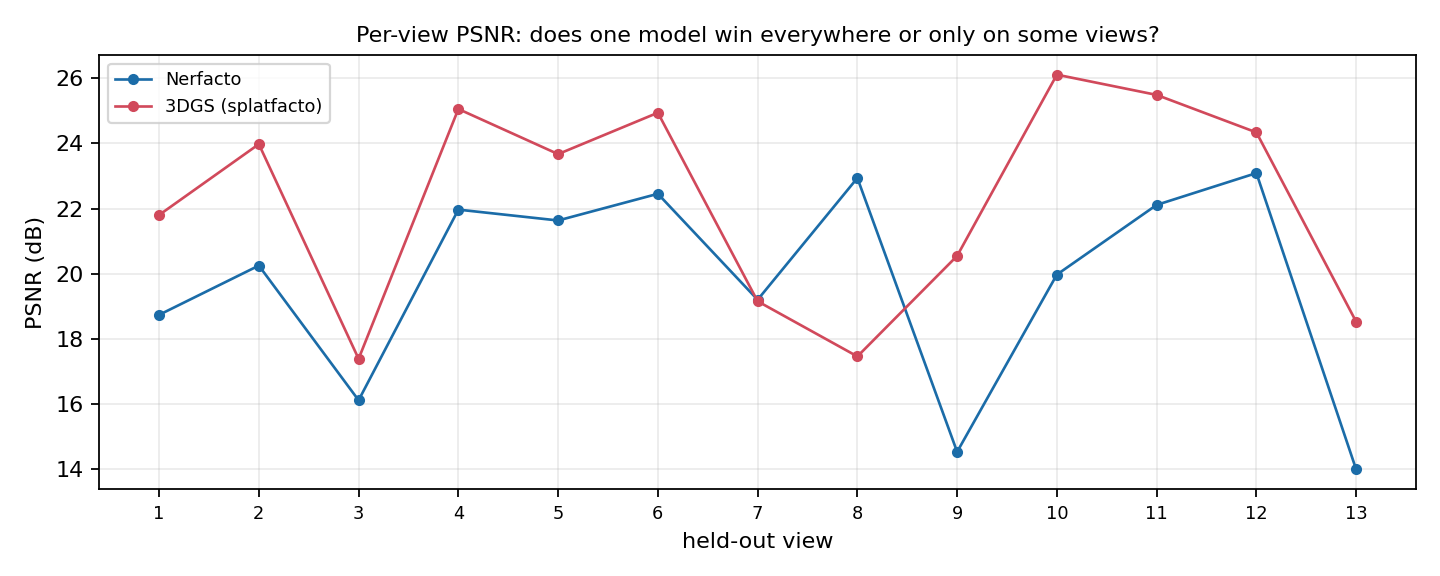

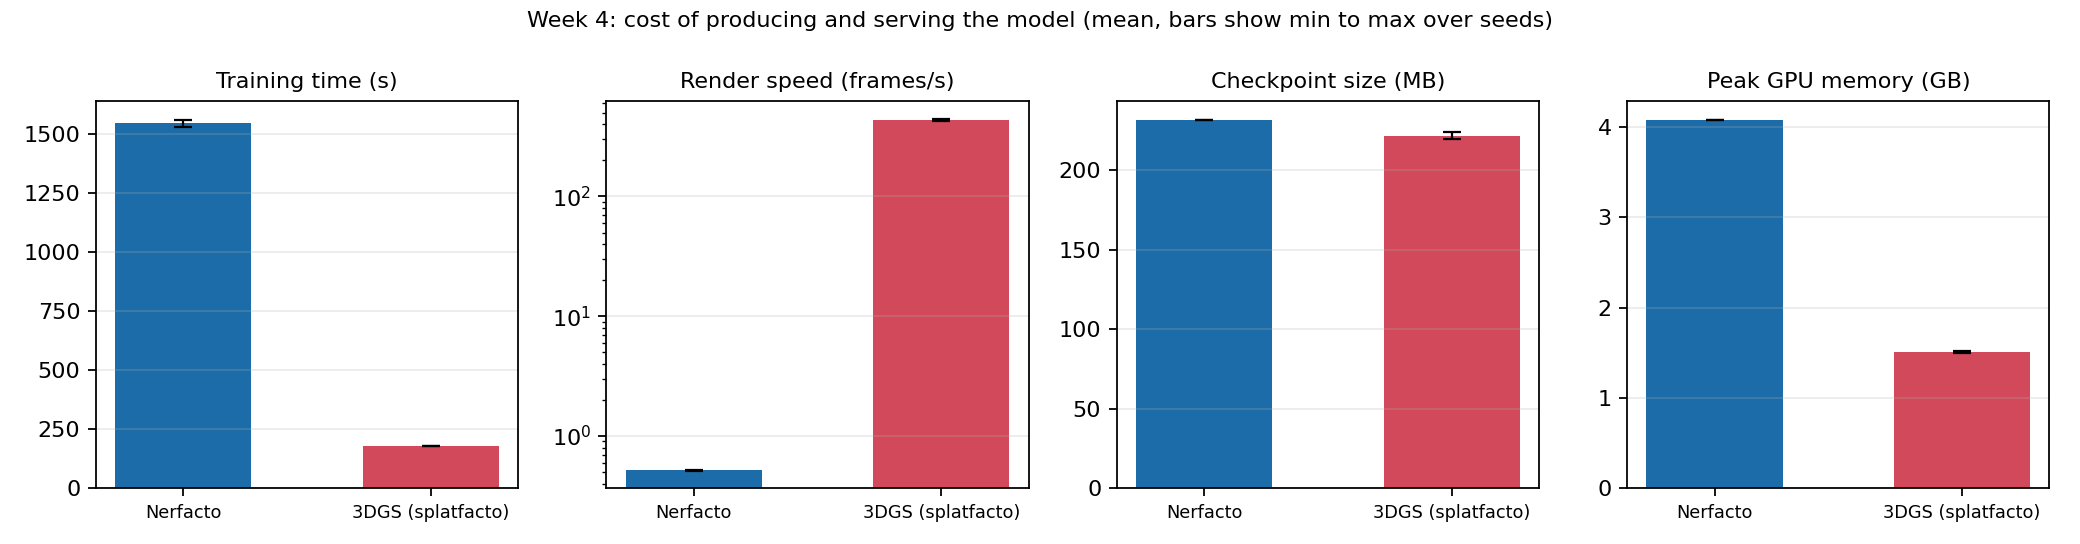

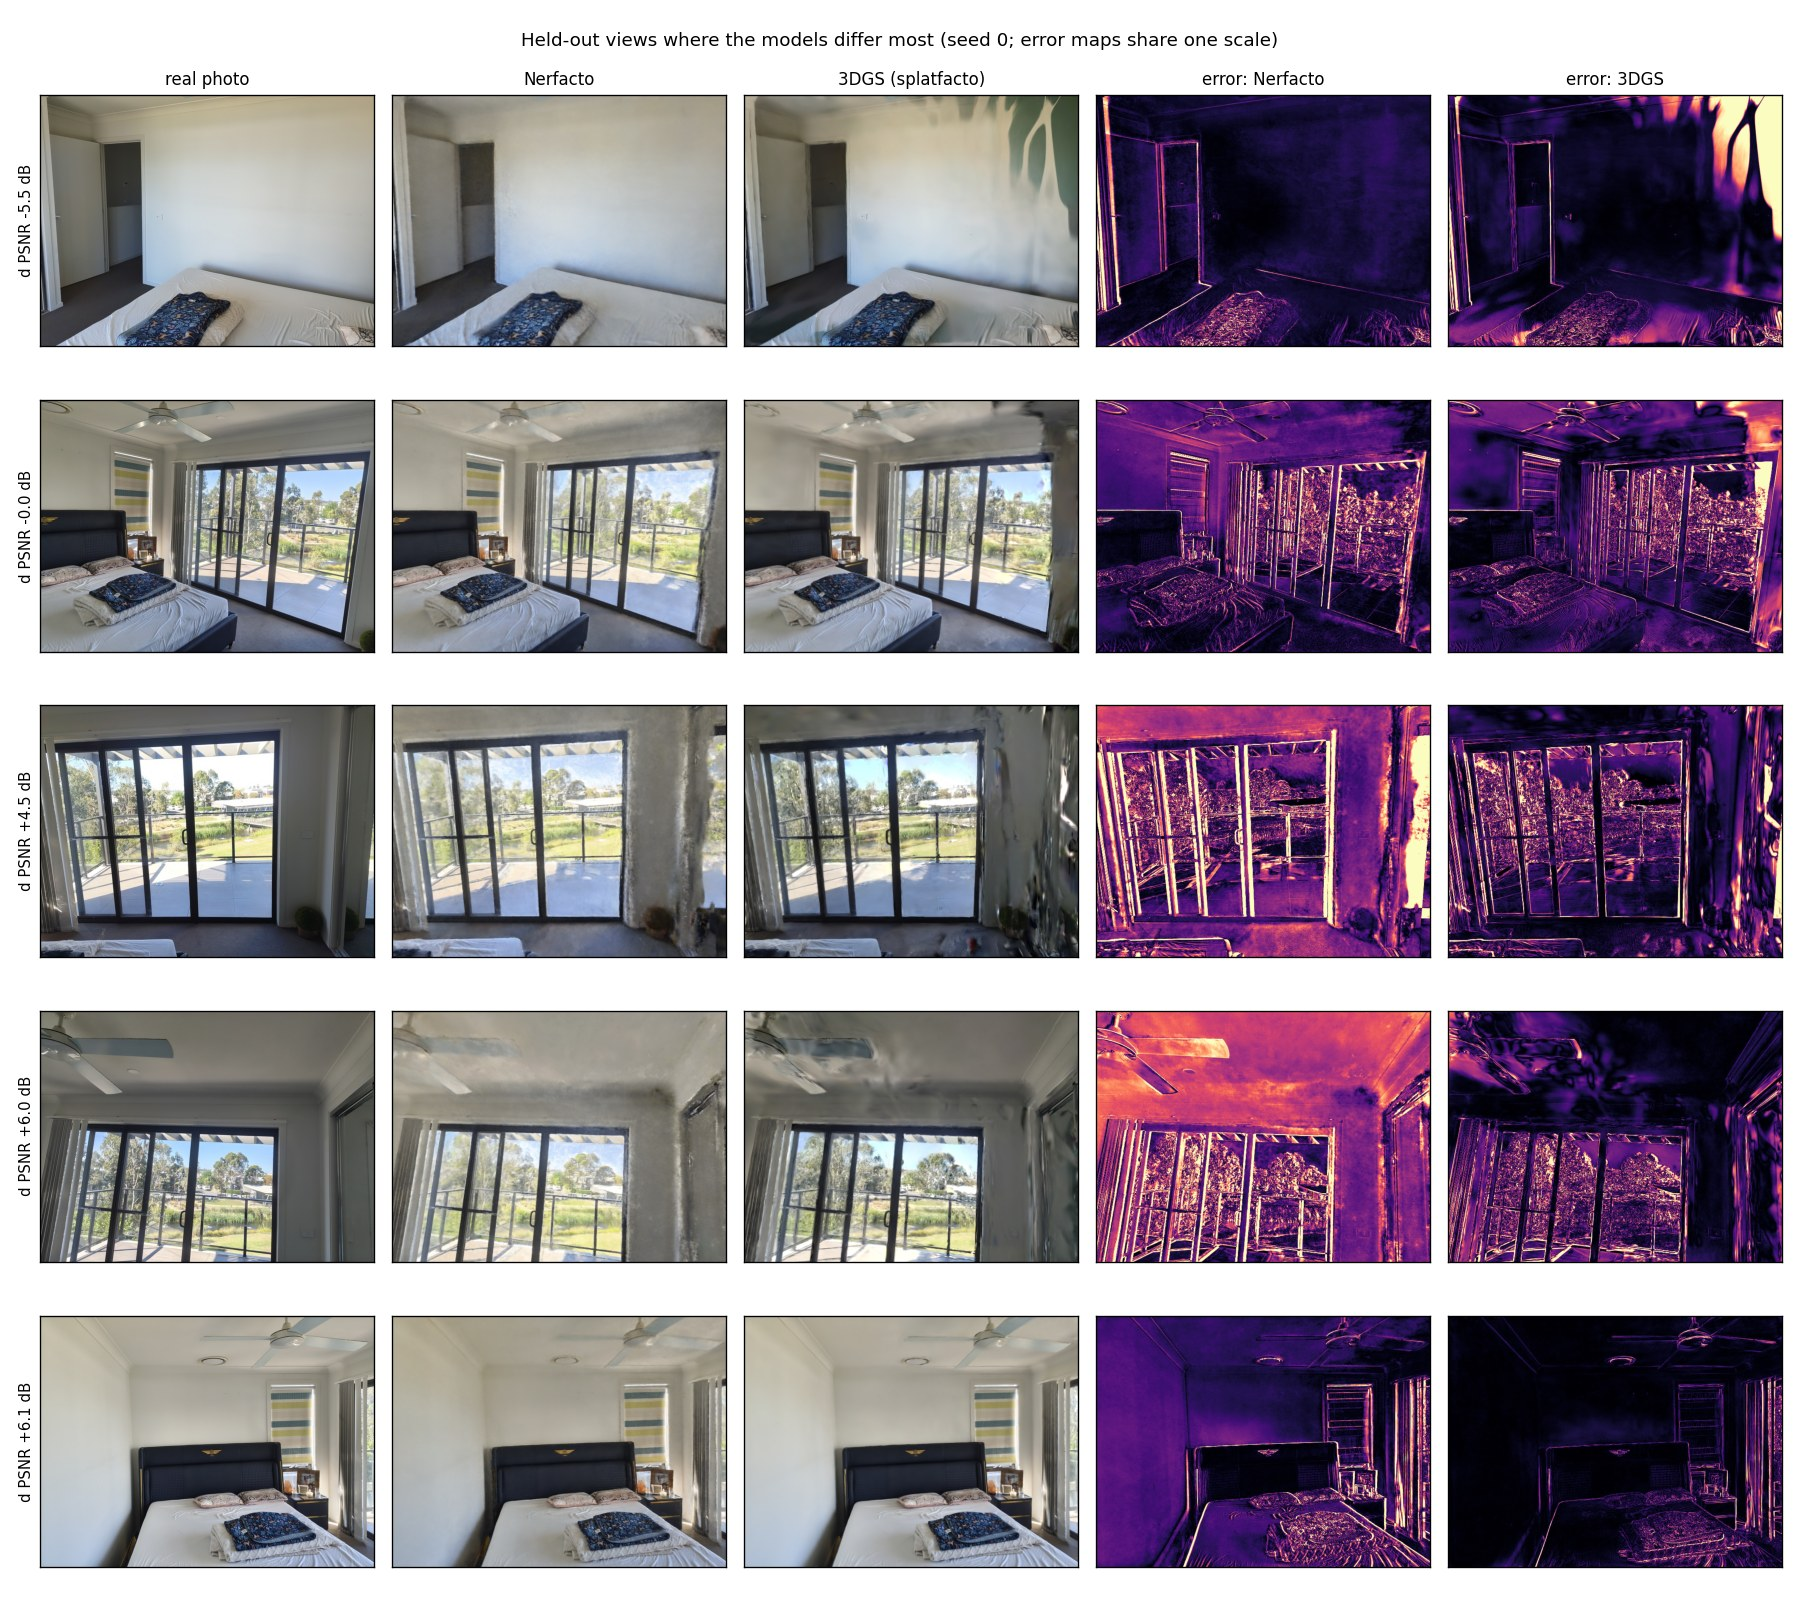

In [25]:
UNITS_PER_HR = None   # e.g. 4.8, from the Resources panel
extra = f'--units-per-hr {UNITS_PER_HR}' if UNITS_PER_HR else ''
!python pairs/w4_nerf_3dgs/report_w4.py {extra} 2>&1 | tee {BASE}/logs/w4_report.log | grep -v Warning
!mkdir -p {BASE}/report_assets && cp -r report_assets/w4 {BASE}/report_assets/
!pip freeze > {BASE}/results/w4_ENV.txt

from IPython.display import Image as IPImage, Video, display
for f in ['w4_quality', 'w4_per_view_psnr', 'w4_cost']:
    display(IPImage(filename=f'report_assets/w4/{f}.png'))
display(IPImage(filename='outputs/w4_figures/w4_qualitative.jpg', width=1100))
import glob
clip = (glob.glob('outputs/w4_figures/w4_side_by_side.*') or [None])[0]
if clip:
    display(Video(clip, embed=True, width=900))


## Last cell: free the GPU
Set `AUTO_DISCONNECT = True` once everything above has finished and been copied to Drive. (Runtime > Manage sessions > Terminate does the same.)


In [27]:
AUTO_DISCONNECT = True
if AUTO_DISCONNECT:
    from google.colab import runtime
    runtime.unassign()
